In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision.datasets import CIFAR10

In [9]:
# Datasets and DataLoader
from torch.utils.data import DataLoader
from torchvision.transforms import transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

In [10]:
trainset = CIFAR10(root ="./Data", train = True, download = True , transform= transform )
testset = CIFAR10(root ="./Data", train = False, download = True , transform= transform )

100%|██████████| 170M/170M [21:15<00:00, 134kB/s]  


In [11]:
trainloader = DataLoader(trainset,batch_size = 64 , shuffle= True)
testloader = DataLoader(testset,batch_size = 64 )

In [12]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN , self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3 , padding =1 ),
            nn.ReLU(),
            nn.MaxPool2d(2,2) ,# kernel , stride=2
    
            nn.Conv2d(32,64,kernel_size=3, padding =1),
            nn.ReLU(),
            nn.MaxPool2d(2,2),

            nn.Conv2d(64,128,kernel_size=3, padding =1),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
           )

        self.fc_layers = nn.Sequential(
            nn.Linear(4*4*128, 256),
            nn.ReLU(),

            nn.Linear(256 , 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0),-1)
        x = self.fc_layers(x)

        return x

    

In [13]:
model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

In [14]:
train_losses = []
val_losses = []
best_loss_val = float("inf")

epochs = 10

for epoch in range(epochs):
    running_loss = 0.0

    for images, labels in trainloader:
        optimizer.zero_grad()
        
        output = model.forward(images) # FP
        loss = criterion(output, labels) # loss fnx
        loss.backward() # BP
        optimizer.step() # update params

        running_loss += loss.item()

    epoch_training_loss = running_loss/len(trainloader)
    train_losses.append(epoch_training_loss)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images , labels in testloader:
            output = model.forward(images)
            loss = criterion(output , labels)
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss/len(testloader)
    val_losses.append(epoch_val_loss)

    # print(f"epoch{epoch+1}/{epochs}==> train loss = {epoch_training_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_loss_val:
        best_loss_val = epoch_val_loss

        torch.save(model.state_dict(), "Best_model.pt")

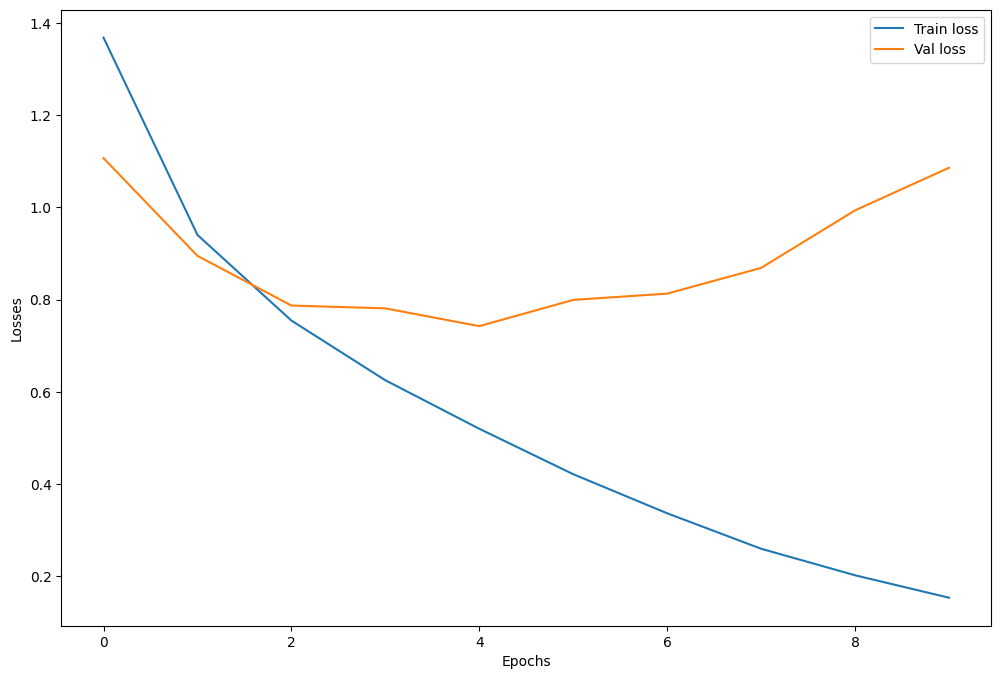

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
loss_df = pd.DataFrame({
    "Train losses" : train_losses,
    "Val losses" : val_losses
})
plt.figure(figsize=(12,8))
plt.plot(loss_df["Train losses"] , label= "Train loss")
plt.plot(loss_df["Val losses"] , label= "Val loss")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

In [16]:
correct_labels = 0
total_labels = 0 

with torch.no_grad():
    for images , labels in testloader :
        output = model.forward(images)
        _, predicted = torch.max(output , 1)
        
        correct_labels+= (predicted == labels).sum().item()
        total_labels += labels.size(0)

    print(f"Accuracy = {(correct_labels/total_labels) * 100}")

Accuracy = 75.53999999999999
